# PDP Strikethrough vs Clean Pricing — A/B read-out

**Experiment 201 · ecom · Product Detail Page · 28-day enrollment (2026-05-01 → 2026-05-29) · 7-day per-customer conversion window**

Merchandising wants a struck-through MRP + "Save X%" badge on the PDP (urgency → conversion). Brand pushes back (cheapens us, attracts deal-seekers who churn). This notebook settles it — and the answer is more interesting than either side expected: **the lift is real, but it breaches a guardrail we committed to in advance, so the rigorous call is a monitored, single-segment rollout, not a global ship.**

Order is deliberate: **validity first (SRM, exposure), then the primary test, then segments, then the cost side.** No conversion number is read before SRM passes.

In [1]:
from pathlib import Path
import sys, duckdb, numpy as np, pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "seed_experiment.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "analysis")); sys.path.insert(0, str(ROOT))
import stats as ab
import make_figures as mk            # one source of truth for the charts

con = duckdb.connect(str(ROOT / "data" / "experiment.duckdb"), read_only=True)
sql = lambda f: con.execute((ROOT / "sql" / f).read_text()).df()
FIG = ROOT / "figures"

# (Re)render the three figures from the data so the notebook and README never drift.
mk.apply_theme(); _a,_o = mk._load_tables(); _cust = mk._customer_outcomes(_a,_o); M = mk.compute_metrics(_cust)
mk.fig1_forest(M); mk.fig2_dumbbell(M); mk.fig3_guardrails(M)
print("figures rendered from data")

figures rendered from data


## 1. Validity — Sample Ratio Mismatch (SRM)
If the 50/50 split didn't hold, randomization is broken and nothing downstream is trustworthy. Chi-square first, before any conversion number.

In [2]:
srm = sql("01_srm_check.sql"); display(srm)
n_c = int(srm.loc[srm.variant_name=="control","n"].iloc[0])
n_t = int(srm.loc[srm.variant_name=="treatment","n"].iloc[0])
chi2, p_srm = ab.chisq_srm(n_c, n_t)
print(f"chi-square = {chi2:.3f}, p = {p_srm:.3f}")
assert p_srm >= 0.001, "SRM FAILED — stop, investigate randomization"
print("SRM OK — split within tolerance, proceed.")

,variant_name,n,total,observed_share,expected_share
0,control,25047,50000.0,0.5009,0.5
1,treatment,24953,50000.0,0.4991,0.5


chi-square = 0.177, p = 0.674
SRM OK — split within tolerance, proceed.


## 2. Exposure — ITT vs ATT
Not everyone assigned saw the PDP. We gate on **intent-to-treat** (all assigned — conservative, no cherry-picking); ATT is reported alongside. Exposure should be high and *balanced* across arms.

In [3]:
display(sql("02_exposure_itt_att.sql"))
print("Exposure ~92% and balanced across arms → ITT and ATT agree; we gate on ITT.")

,variant_name,assigned,actually_exposed,exposure_rate
0,control,25047,22971,0.9171
1,treatment,24953,22991,0.9214


Exposure ~92% and balanced across arms → ITT and ATT agree; we gate on ITT.


## 3. Primary metric — conversion, lift, 95% CI
Randomization unit = customer, so the analysis unit is the customer (one row per customer: did they place ≥1 paid order within 7 days of assignment). Absolute **and** relative lift, both with CIs.

In [4]:
m = sql("03_per_variant_metrics.sql").set_index("variant_name"); display(m)
x_c, x_t = int(m.loc["control","converters"]), int(m.loc["treatment","converters"])
N_c, N_t = int(m.loc["control","customers"]), int(m.loc["treatment","customers"])
r = ab.lift_with_ci(x_c, N_c, x_t, N_t)
print(f"Control {r.p_control:.4f} | Treatment {r.p_treatment:.4f}")
print(f"Absolute {r.abs_lift:+.4f} (95% CI {r.abs_ci[0]:+.4f}…{r.abs_ci[1]:+.4f})")
print(f"Relative {r.rel_lift:+.1%} (95% CI {r.rel_ci[0]:+.1%}…{r.rel_ci[1]:+.1%}) | Z={r.z:.2f}, p={r.p_value:.3f}")

,customers,converters,conversion_rate,revenue,revenue_per_customer,aov,refund_rate,repeat_30d_rate,pmt_failure_rate
variant_name,,,,,,,,,
control,25047,957.0,0.0382,2800672.0,111.82,2926.51,0.0104,0.2257,0.0162
treatment,24953,1066.0,0.0427,2871193.0,115.06,2693.43,0.0206,0.1904,0.0174


Control 0.0382 | Treatment 0.0427
Absolute +0.0045 (95% CI +0.0011…+0.0080)
Relative +11.8% (95% CI +2.8%…+20.9%) | Z=2.56, p=0.010


The lift is real and its CI clears zero; Z sits in the believable 2–3 band (not 70 — a sanity check the seeded effect and N are realistic).

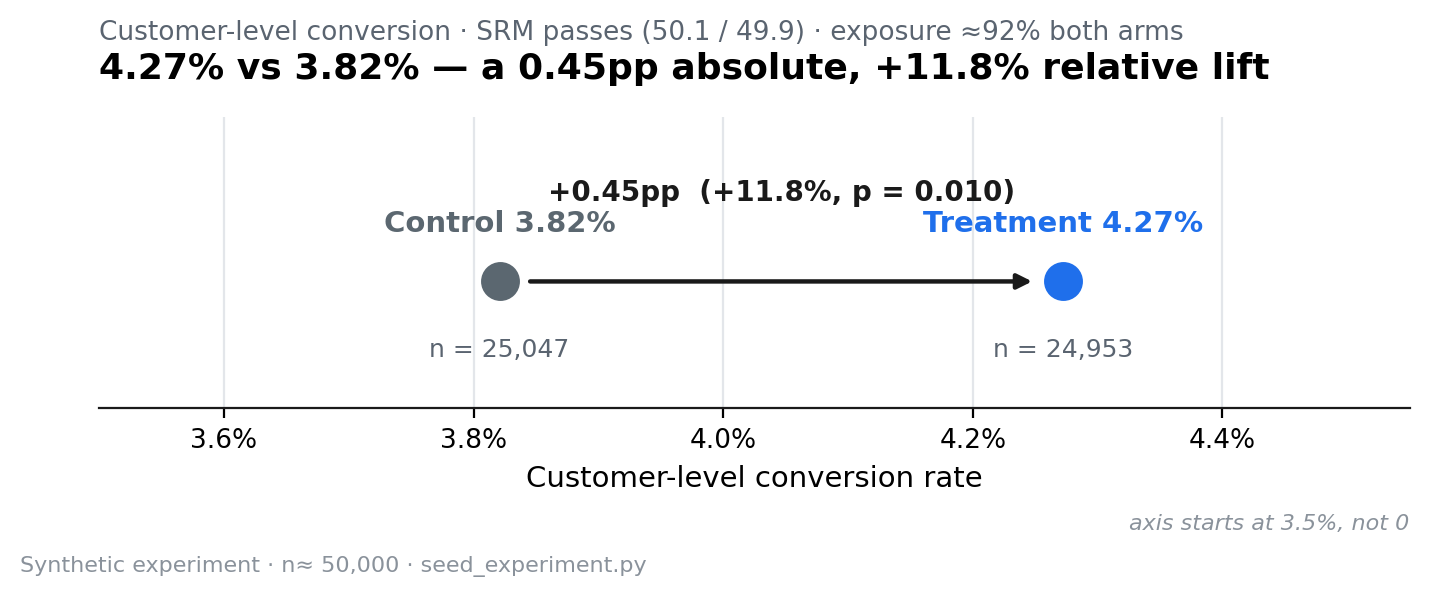

In [5]:
display(Image(filename=str(FIG/"02_conversion_compare.png")))

## 4. Power reality-check
Before trusting it: could this test even detect an effect in the realistic band? Strikethrough rarely moves conversion more than ~3–12% relative.

In [6]:
baseline = r.p_control
n_needed = ab.required_sample_per_arm(baseline, mde_abs=0.005)
mde_here = ab.detectable_mde_abs(baseline, n_per_arm=N_c)
print(f"0.5pp MDE (~{0.005/baseline:.0%} rel) at 80% power needs ~{n_needed:,}/arm.")
print(f"We have ~{N_c:,}/arm → smallest detectable effect ≈ {mde_here:.4f} abs ({mde_here/baseline:.0%} rel).")
print("Powered for the overall effect band. (Segment-level, the test is underpowered — see §6.)")

0.5pp MDE (~13% rel) at 80% power needs ~24,517/arm.
We have ~25,047/arm → smallest detectable effect ≈ 0.0048 abs (13% rel).
Powered for the overall effect band. (Segment-level, the test is underpowered — see §6.)


## 5. Segmentation + Bonferroni — where the lift lives
Every segment is another test, so we correct for multiple comparisons before acting on any single cut.

In [7]:
seg = sql("04_segmentation.sql")
cuts = seg["cut"].unique()
n_tests = sum(seg[seg.cut==cu]["segment"].nunique() for cu in cuts)
alpha_adj = ab.bonferroni_alpha(0.05, n_tests)
rows=[]
for cu in cuts:
    for s in sorted(seg[seg.cut==cu]["segment"].unique()):
        d = seg[(seg.cut==cu)&(seg.segment==s)]
        cc=d[d.variant_name=="control"]; tt=d[d.variant_name=="treatment"]
        res=ab.lift_with_ci(int(cc.converters.iloc[0]),int(cc.customers.iloc[0]),
                            int(tt.converters.iloc[0]),int(tt.customers.iloc[0]))
        rows.append({"cut":cu,"segment":s,"rel_lift":f"{res.rel_lift:+.1%}",
                     "p":round(res.p_value,4),"sig_after_bonferroni":res.p_value<alpha_adj})
print(f"{n_tests} tests → Bonferroni α = {alpha_adj:.4f}")
display(pd.DataFrame(rows))

9 tests → Bonferroni α = 0.0056


,cut,segment,rel_lift,p,sig_after_bonferroni
0,category,apparel_beauty,+14.3%,0.0188,False
1,category,electronics,-2.7%,0.7956,False
2,category,home,+17.3%,0.0712,False
3,country,India,+11.4%,0.0276,False
4,country,Other,+3.0%,0.8476,False
5,country,United States,+19.6%,0.1335,False
6,device,desktop,+15.2%,0.0487,False
7,device,mobile,+10.4%,0.0858,False
8,device,tablet,+5.4%,0.7730,False


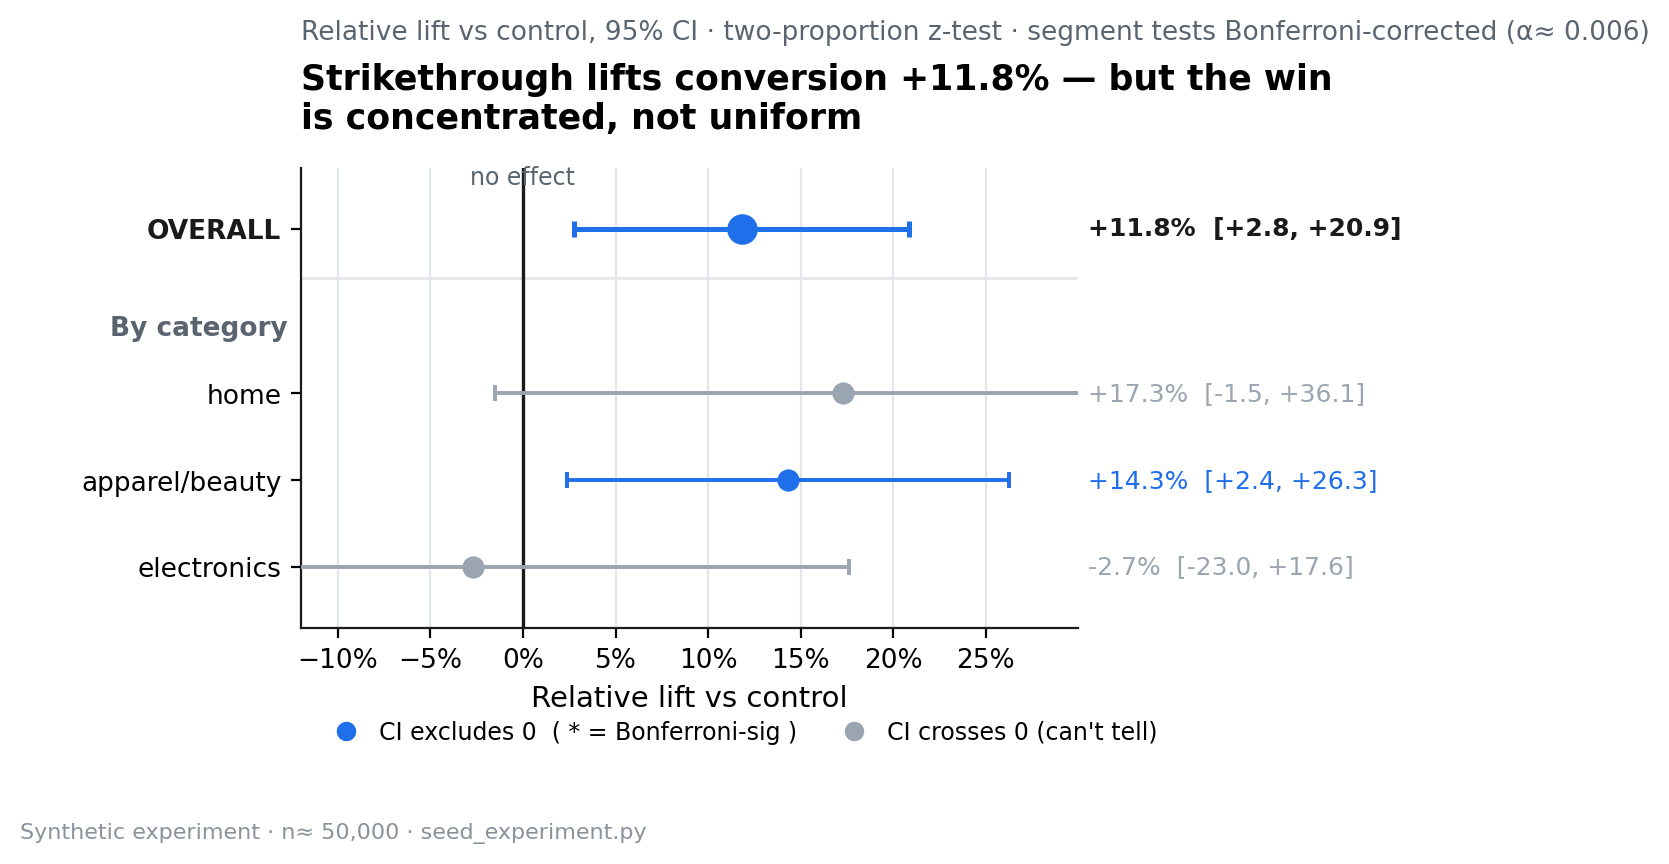

In [8]:
display(Image(filename=str(FIG/"01_lift_forest.png")))

**Read:** the lift concentrates in apparel/beauty (+14%, CI excludes zero unadjusted) and reverses on electronics (−3%). **But no segment survives Bonferroni** — the experiment is powered for the overall effect, not for slicing. So the heterogeneity is a *direction to confirm*, not a proven per-segment result. That's why the recommendation is a confirmatory rollout, not an immediate per-segment ship.

### Heterogeneity, not Simpson's
One quick guard: a Simpson's artefact would show the aggregate contradicting the segments. It doesn't here — the overall lift agrees with most segments — so the cut is a real heterogeneous effect, not an averaging illusion.

In [9]:
cat = [x for x in rows if x["cut"]=="category"]
overall_pos = r.rel_lift > 0
dirs = {x["segment"]: x["rel_lift"] for x in cat}
print("Overall positive:", overall_pos, "| category lifts:", dirs)
print("Aggregate agrees with the majority of segments → heterogeneous effect, not Simpson's paradox.")

Overall positive: True | category lifts: {'apparel_beauty': '+14.3%', 'electronics': '-2.7%', 'home': '+17.3%'}
Aggregate agrees with the majority of segments → heterogeneous effect, not Simpson's paradox.


## 6. Why "no peeking" is in the pre-registration
Concretely: run the experiment many times under the *null* (no true effect) and allow stopping early on significance at interim looks. With no peeking the false-positive rate is the nominal ~5%; with peeking it climbs toward ~10%. This is the inflation the fixed-N stopping rule exists to prevent.

In [10]:
rng = np.random.default_rng(7)
base = r.p_control
N_arm, n_sims, looks = 12000, 1000, [0.25, 0.5, 0.75, 1.0]
fp_fixed = fp_peek = 0
for _ in range(n_sims):
    # null: both arms share the same rate
    c_out = rng.random(N_arm) < base
    t_out = rng.random(N_arm) < base
    sig_any = False
    for f in looks:
        k = int(N_arm*f)
        z,p = ab.two_proportion_ztest(int(c_out[:k].sum()),k,int(t_out[:k].sum()),k)
        if p < 0.05: sig_any = True
        if f == 1.0 and p < 0.05: fp_fixed += 1
    if sig_any: fp_peek += 1
print(f"Fixed-N (look once, at the end): false-positive rate {fp_fixed/n_sims:.1%}  (target ~5%)")
print(f"Peeking (stop on first sig over {len(looks)} looks): false-positive rate {fp_peek/n_sims:.1%}")
print("→ Peeking nearly doubles the false-positive rate. A real mid-flight read needs an")
print("  alpha-spending design (mSPRT / O'Brien–Fleming), not an ad-hoc look — see DESIGN.md.")

Fixed-N (look once, at the end): false-positive rate 5.8%  (target ~5%)
Peeking (stop on first sig over 4 looks): false-positive rate 13.9%
→ Peeking nearly doubles the false-positive rate. A real mid-flight read needs an
  alpha-spending design (mSPRT / O'Brien–Fleming), not an ad-hoc look — see DESIGN.md.


## 7. Guardrails — the reason this isn't a simple ship
The primary metric is up, but strikethrough is exactly the change you'd expect side-effects from. Quantify them against the line we drew in advance.

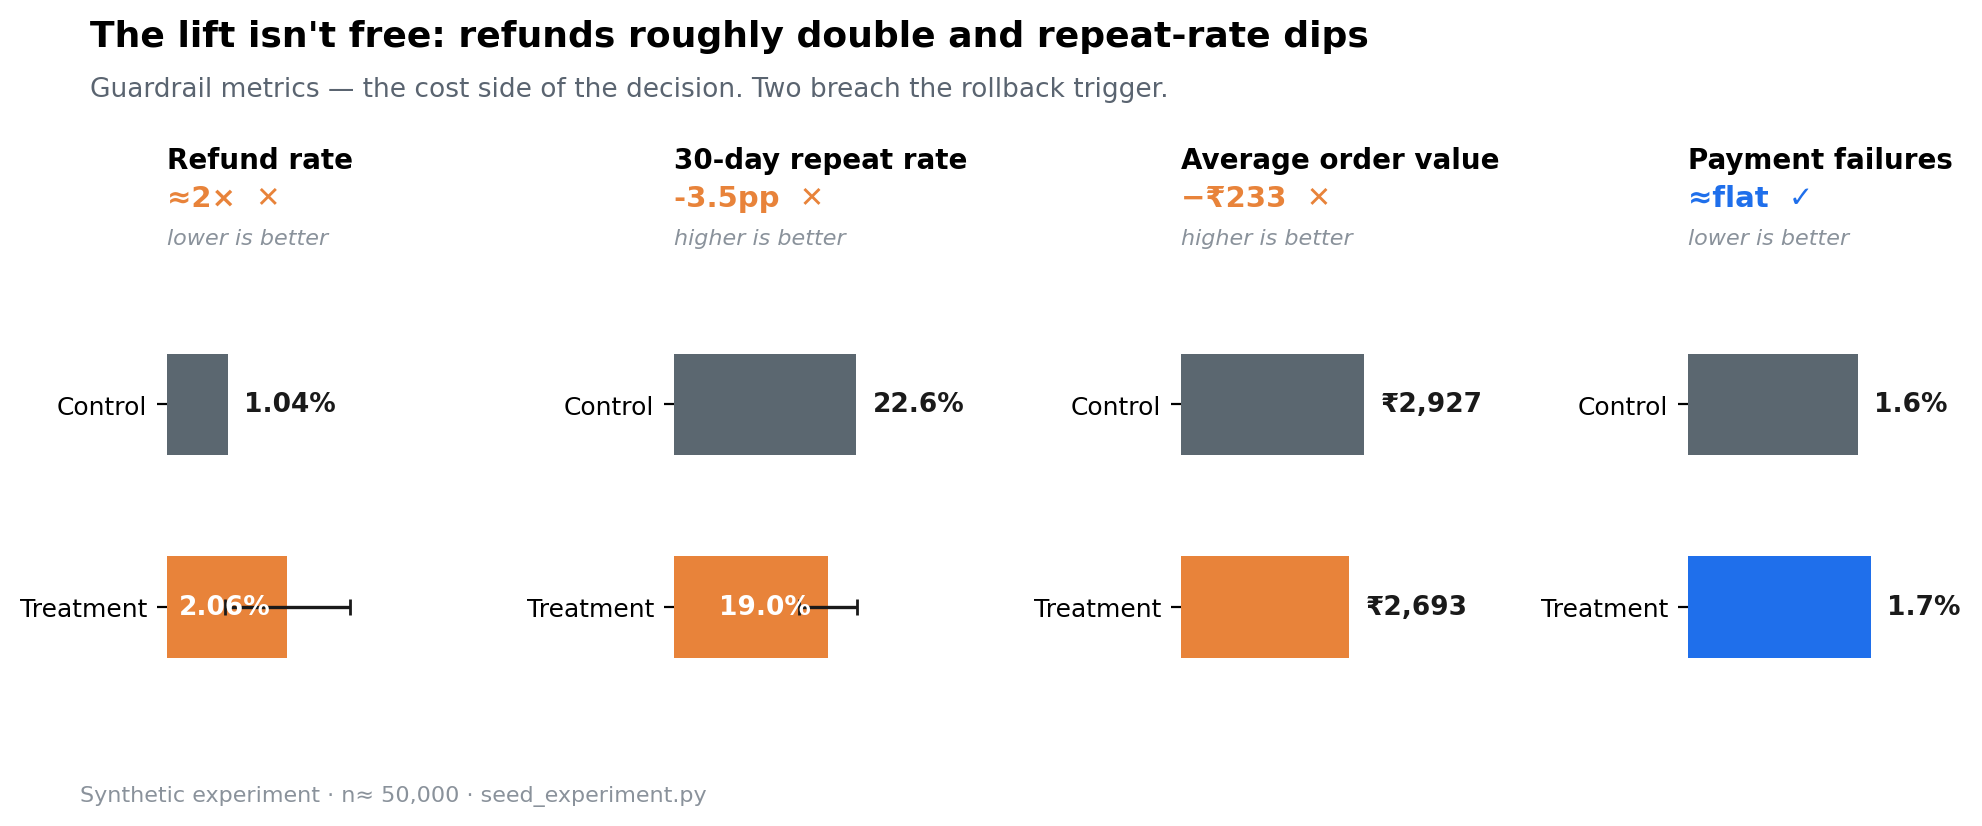

,refund_rate,repeat_30d_rate,aov,pmt_failure_rate
variant_name,,,,
control,0.0104,0.2257,2926.51,0.0162
treatment,0.0206,0.1904,2693.43,0.0174


Refund 1.04%→2.06% (tol +0.3pp) | Repeat 22.6%→19.0% (tol -1pp)
Both BREACH the pre-registered tolerance — the decision rule says a breach blocks an unconditional ship.


In [11]:
display(Image(filename=str(FIG/"03_guardrails.png")))
g = m[["refund_rate","repeat_30d_rate","aov","pmt_failure_rate"]]; display(g)
print(f"Refund {m.loc['control','refund_rate']:.2%}→{m.loc['treatment','refund_rate']:.2%} "
      f"(tol +0.3pp) | Repeat {m.loc['control','repeat_30d_rate']:.1%}→{m.loc['treatment','repeat_30d_rate']:.1%} (tol -1pp)")
print("Both BREACH the pre-registered tolerance — the decision rule says a breach blocks an unconditional ship.")

## 8. Verdict

- **Primary metric won:** +11.8% relative (Z = 2.56, **p = 0.010**, 95% CI +2.8%…+20.9% — excludes zero).
- **But two guardrails breach** the pre-registered tolerance (refund 1.0%→2.1%, repeat 22.6%→19.0%), and **no segment survives Bonferroni** — the lift concentrates in apparel/beauty but isn't proven per-segment.
- **Decision (per the committed rule):** don't ship globally, don't kill it. **Run a monitored, apparel/beauty-only confirmatory rollout** with a refund kill-switch (pause if refund > 3.0% sustained 3+ days); **hold** home (underpowered) and electronics (no gain, worse guardrails).

The headline isn't the p-value — it's holding the line on a guardrail we set before the data, instead of overriding it to claim a win. Full reasoning, money sizing, and rollback plan in **[`decision_memo.md`](../decision_memo.md)**.